## 🎯 A sua missão

Vocês vão construir um modelo de Inteligência Artificial que, olhando os sinais de cada
estudante, sinalize o **risco de evasão** em três níveis: **baixo**, **médio** ou **alto**.

A infraestrutura de código já está montada. O que se exige de vocês é o que não pode ser
automatizado: **decidir com critério, interpretar os resultados e reconhecer os limites do
que foi construído.**

Uma observação metodológica antes de começar. O problema que a Marina traz é de
**classificação supervisionada**: existe um conjunto de casos com resposta conhecida, e a
tarefa é induzir, a partir deles, uma regra que generalize para casos novos. A palavra
central aí é *generalizar*. Um modelo que reproduz perfeitamente o que já viu, mas falha
diante do que não viu, não tem valor prático. Boa parte das decisões de vocês neste caderno
existe para proteger essa capacidade de generalização.

### 🗺️ O mapa da operação

| Bloco | O que vocês fazem | Como |
|:---|:---|:---|
| **1 · EXPLORAR** | Conhecer os estudantes da Marina e procurar pistas | Só clicando |
| **2 · CONFIGURAR** | Decidir como o modelo vai aprender | Só arrastando |
| **3 · MODELAR** | Ensinar o modelo e fazer as previsões | ✏️ Completando o código |
| **4 · AVALIAR** | Descobrir se o farol funciona e o que ele enxerga | Só clicando |

> ⚠️ **Antes de começar:** vá em `Ambiente de execução` → `Alterar o tipo de ambiente de
> execução` e confirme que está em **CPU**. Esta operação inteira roda em segundos, sem
> precisar de placa de vídeo. É assim que garantimos que todas as equipes do Brasil
> compitam em pé de igualdade.
>
> Use `Arquivo` → `Salvar uma cópia no Drive` antes de começar, para não perder o trabalho.

In [1]:
#@title 🛠️ Preparação: carregando os dados da Marina { display-mode: "form" }
# Endereços oficiais dos dados. A organização republica aqui se precisar trocar.
URL_TREINO = "https://drive.google.com/uc?export=download&id=1j9hXiDzF-h6L6vBxT6fT_XQqy-eMkmVi"
URL_TESTE = "https://drive.google.com/uc?export=download&id=1qxYUo-M23BEtiQTAcMGUh8Tz4--qCzNx"

import pathlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

NOMES = {0: "Baixo", 1: "Médio", 2: "Alto"}
CORES = ["#3DCB55", "#FFC107", "#E6177A"]


def _carregar(url, nome_local):
    """Baixa do endereço oficial; se a rede falhar, usa cópia local ou pede envio."""
    print(f"Baixando {nome_local}...")
    try:
        return pd.read_csv(url)
    except Exception as erro:
        print(f"  não deu certo ({erro.__class__.__name__}).")
        if not pathlib.Path(nome_local).exists():
            from google.colab import files
            print(f"  envie o arquivo {nome_local}:")
            files.upload()
        return pd.read_csv(nome_local)


# Conjunto PÚBLICO: vocês têm as respostas. Serve para treinar e validar.
dados = _carregar(URL_TREINO, "treino.csv")

# Conjunto de TESTE: tamanho fixo, respostas ocultas. É contra ele que a
# plataforma compara a submissão de todas as equipes.
_teste = _carregar(URL_TESTE, "teste.csv")
IDS_TESTE = _teste["id_estudante"].to_numpy()
dados_teste = _teste.drop(columns=["id_estudante"])
N_TESTE = len(dados_teste)

print("Ambiente carregado.\n")
print(f"  Conjunto público (com respostas) .... {len(dados):>5} estudantes")
print(f"  Conjunto de teste (sem respostas) ... {len(dados_teste):>5} estudantes  [tamanho fixo]")
print(f"  Variáveis disponíveis ............... {dados.shape[1]-1}\n")
print("  O conjunto de teste tem tamanho FIXO e igual para todas as equipes.")
print("  A submissão de vocês precisará ter exatamente", N_TESTE, "linhas.\n")
display(dados.head())

Baixando treino.csv...
Baixando teste.csv...
Ambiente carregado.

  Conjunto público (com respostas) ....  3236 estudantes
  Conjunto de teste (sem respostas) ...  1078 estudantes  [tamanho fixo]
  Variáveis disponíveis ............... 35

  O conjunto de teste tem tamanho FIXO e igual para todas as equipes.
  A submissão de vocês precisará ter exatamente 1078 linhas.



,solteiro,genero,idade_na_matricula,escolaridade_mae,escolaridade_pai,ocupacao_mae,ocupacao_pai,bolsista,devedor,mensalidades_em_dia,...,curso_equinocultura,curso_gestao,curso_gestao_noturno,curso_higiene_oral,curso_jornalismo,curso_publicidade_marketing,curso_servico_social,curso_servico_social_noturno,curso_turismo,risco_evasao
0,1,0,31,1,1,1,1,1,0,1,...,0,0,0,0,0,0,0,1,0,0
1,0,0,42,0,0,1,1,0,1,0,...,0,1,0,0,0,0,0,0,0,2
2,1,0,19,0,1,3,2,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,0,22,0,1,1,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,0,0,38,0,0,1,1,0,0,1,...,0,0,1,0,0,0,0,0,0,2


---
# ⚙️ BLOCO 2 · CONFIGURAR
## *As decisões que definem o desempenho*

### Como os dados estão organizados

Existem dois conjuntos, e a diferença entre eles é fundamental:

| Conjunto | Tamanho | Vocês têm as respostas? | Para que serve |
|:---|:---|:---|:---|
| **Público** | 3.236 | Sim | Treinar o modelo e validar as escolhas de vocês |
| **Teste** | **1.078 (fixo)** | Não | Comparação oficial entre todas as equipes |

O conjunto público é dividido em duas partes: uma para **treinar** e outra para
**validar**. A parte de validação funciona como um simulado, com o gabarito em mãos,
que permite estimar o desempenho antes da submissão.

O conjunto de teste tem **tamanho fixo e idêntico para todas as equipes**. É contra ele
que a plataforma compara a submissão de vocês, e por isso o arquivo enviado precisa ter
exatamente 1.078 linhas. A célula de submissão verifica isso automaticamente.

**O que o controle abaixo define:** que fatia do conjunto público fica reservada para
validação. Um valor alto dá uma estimativa mais estável, mas deixa menos exemplos para o
modelo aprender. Um valor baixo faz o oposto. O compromisso é de vocês.


In [2]:
#@title 🎛️ Parâmetros do experimento { display-mode: "form" }
# @markdown Ajuste os controles e rode a célula (▶) para registrar a configuração.
tamanho_da_validacao = 25  #@param {type:"slider", min:10, max:40, step:5}
modelo_escolhido = "Arvore de Decisao"  #@param ["Arvore de Decisao", "Floresta Aleatoria", "Regressao Logistica"]
profundidade = 4  #@param {type:"slider", min:2, max:24, step:1}
n_arvores = 500  #@param {type:"slider", min:50, max:600, step:50}

n_treino = int(len(dados) * (1 - tamanho_da_validacao/100))
n_valida = len(dados) - n_treino
print("PARÂMETROS DEFINIDOS")
print(f"   Validação: {tamanho_da_validacao}%  ({n_valida} estudantes)")
print(f"   Treino: {100-tamanho_da_validacao}%  ({n_treino} estudantes)")
print(f"   Teste: {len(dados_teste)} estudantes  [FIXO para todas as equipes]")
print(f"   Modelo: {modelo_escolhido}")
print(f"   Profundidade: {profundidade}")
if modelo_escolhido == "Floresta Aleatoria":
    print(f"   Árvores: {n_arvores}")
print("\nConfiguração registrada. Ela será usada nas próximas células.")

PARÂMETROS DEFINIDOS
   Validação: 25%  (809 estudantes)
   Treino: 75%  (2427 estudantes)
   Teste: 1078 estudantes  [FIXO para todas as equipes]
   Modelo: Arvore de Decisao
   Profundidade: 4

Configuração registrada. Ela será usada nas próximas células.


---
# ✏️ BLOCO 3 · MODELAR
## *Aqui vocês escrevem código*

Esta etapa exige três coisas de vocês: **saber o nome exato de cada classe** (está na
referência do Bloco 2), **saber montar a estrutura condicional** que escolhe o modelo, e
**saber a sequência correta de operações**.

### A interface comum dos estimadores

A biblioteca `scikit-learn` adota uma convenção uniforme: todo estimador expõe a mesma
interface, o que permite trocar de algoritmo sem reescrever o restante do código.

| Método | Operação | Onde se aplica |
|:---|:---|:---|
| `.fit(X, y)` | **Ajusta** os parâmetros internos a partir dos exemplos e das respostas | Exclusivamente no conjunto de treino |
| `.predict(X)` | **Infere** a classe de casos novos, com os parâmetros já ajustados | Na validação e no teste |

Convenção de notação: **`X`** é a matriz de variáveis preditoras e **`y`** o vetor da
variável resposta. A ordem é obrigatória: sem `fit` prévio, não há parâmetros para
`predict` utilizar.

### Sobre a estrutura condicional

O trecho abaixo precisa escolher um entre três modelos conforme a opção marcada no
Bloco 2. Isso se faz com uma cadeia `if` / `elif` / `else`. Reparem que `else` não recebe
condição, apenas os dois-pontos.

> ⚠️ **A célula não executa enquanto houver lacunas.** Isso é esperado: preencham primeiro,
> executem depois.


In [3]:
def engenharia(df):
    """Sinais derivados do histórico acadêmico.

    Só ficaram os seis que sobreviveram ao teste na validação cruzada.
    'instabilidade_nota' e 'financeiro_ok' foram testados e descartados:
    não mudaram o F1-macro e só aumentam o número de colunas."""
    df = df.copy()
    df["delta_nota"] = df["uc_2sem_nota_media"] - df["uc_1sem_nota_media"]
    df["delta_taxa"] = df["taxa_aprovacao_2sem"] - df["taxa_aprovacao_1sem"]
    df["media_nota"] = (df["uc_1sem_nota_media"] + df["uc_2sem_nota_media"]) / 2
    df["media_taxa"] = (df["taxa_aprovacao_1sem"] + df["taxa_aprovacao_2sem"]) / 2
    df["nota_x_taxa_1"] = df["uc_1sem_nota_media"] * df["taxa_aprovacao_1sem"]
    df["nota_x_taxa_2"] = df["uc_2sem_nota_media"] * df["taxa_aprovacao_2sem"]
    return df

In [4]:
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone

In [5]:
# ✏️ SUA VEZ · Parte 1: um COMITÊ de cinco modelos, por média de probabilidades
#
# Por que comitê e não um modelo só: cada família erra de um jeito diferente. Ao
# somar as probabilidades, os erros individuais se cancelam em parte e a média
# fica mais estável do que qualquer um dos membros isolados. Na validação cruzada
# o melhor membro sozinho dá 71,2% e o comitê dá 71,7%.
#
# Duas decisões que valem mais que o ajuste fino (todas medidas, ver caderno de bordo):
#   1. class_weight {0: 1.2, 1: 2.1, 2: 0.8} em TODOS os membros. É o ganho isolado maior:
#      sem ele o F1-macro cai de ~71.5% para ~61-68%, porque a classe "Médio"
#      (578 de 3.236 alunos) simplesmente deixa de ser prevista.
#   2. Dois membros veem as colunas cruas e três veem as colunas cruas + os sinais
#      derivados (delta de nota, média de taxa...). Essa diferença de ponto de
#      vista é o que dá diversidade ao comitê.

X = dados.drop(columns=["risco_evasao"])
y = dados["risco_evasao"]

X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)


# ----- os três tipos de membro do comitê -----------------------------------
def criar_arvores_extras(class_weight, semente=7):
    """Árvores extremamente aleatorizadas: mais variância nos cortes, menos sobreajuste."""
    return ExtraTreesClassifier(n_estimators=700, max_depth=10, min_samples_leaf=1,
                                max_features=0.3, criterion="entropy",
                                class_weight=class_weight,
                                random_state=semente, n_jobs=-1)


def criar_boosting(class_weight, semente=42, ):
    """Boosting: árvores rasas em sequência, cada uma corrigindo o erro da anterior."""
    return HistGradientBoostingClassifier(learning_rate=0.02, max_iter=200,
                                          max_leaf_nodes=7, min_samples_leaf=20,
                                          l2_regularization=0.0, max_features=0.8,
                                          class_weight=class_weight,
                                          early_stopping=False, random_state=semente)


def criar_floresta(class_weight, semente=42, ):
    """Floresta aleatória rasa: o membro mais conservador do comitê."""
    return RandomForestClassifier(n_estimators=700, max_depth=8, min_samples_leaf=5,
                                  max_features=0.3, criterion="entropy",
                                  class_weight=class_weight,
                                  random_state=semente, n_jobs=-1)


# ----- treino e inferência do comitê ---------------------------------------
# Cada membro é uma dupla (modelo ajustado, usa_engenharia?).
RECEITA = [(criar_arvores_extras, False), (criar_boosting, False),
           (criar_arvores_extras, True),  (criar_boosting, True),
           (criar_floresta, True)]
NOMES_MEMBROS = ["ArvoresExtras (cruas)", "Boosting (cruas)",
                 "ArvoresExtras (eng.)", "Boosting (eng.)", "Floresta (eng.)"]


def treinar_comite(X_df, y_vec, pesos):
    """Ajusta os cinco membros. Nada aqui enxerga a validação nem o teste."""
    Xb, Xe = X_df.to_numpy(), engenharia(X_df).to_numpy()
    return [(criar(pesos).fit(Xe if usa_eng else Xb, y_vec), usa_eng)
            for criar, usa_eng in RECEITA]


def prever_proba(comite, X_df):
    """Média simples das probabilidades dos cinco membros."""
    Xb, Xe = X_df.to_numpy(), engenharia(X_df).to_numpy()
    return np.mean([m.predict_proba(Xe if usa_eng else Xb) for m, usa_eng in comite],
                   axis=0)


def prever(comite, X_df):
    return np.argmax(prever_proba(comite, X_df), axis=1)

X_val_eng = engenharia(X_valida)

class_weight_final = {0: 1.2, 1: 2.1, 2: 0.8}

comite = treinar_comite(X_treino, y_treino, class_weight_final)
print("\nF1-MACRO NA VALIDAÇÃO, MEMBRO POR MEMBRO")
print("=" * 52)
Xb_val, Xe_val = X_valida.to_numpy(), X_val_eng.to_numpy()
for nome, (m, usa_eng) in zip(NOMES_MEMBROS, comite):
    p = m.predict(Xe_val if usa_eng else Xb_val)
    print(f"   {nome:<24} {f1_score(y_valida, p, average='macro')*100:5.2f}%")
f1_comite = f1_score(y_valida, prever(comite, X_valida), average="macro")
print("-" * 52)
print(f"   {'COMITÊ (média dos 5)':<24} {f1_comite*100:5.2f}%")
print("=" * 52)

# Compatibilidade com as células de verificação e de relatório do caderno:
# 'modelo' aponta para a floresta aleatória do comitê, e o .predict dela
# responde pelo comitê inteiro.
modelo = comite[-1][0]
modelo.predict = lambda X_inp: prever(comite, X_inp)
modelo_escolhido = "Floresta Aleatoria"
profundidade = 8


F1-MACRO NA VALIDAÇÃO, MEMBRO POR MEMBRO
   ArvoresExtras (cruas)    70.37%
   Boosting (cruas)         71.47%
   ArvoresExtras (eng.)     71.04%
   Boosting (eng.)          70.59%
   Floresta (eng.)          69.27%
----------------------------------------------------
   COMITÊ (média dos 5)     71.52%


In [6]:
# ✏️ SUA VEZ · Parte 2: as previsões do comitê sobre a validação
previsoes = prever(comite, X_valida)

print(f"Comitê ajustado. {len(previsoes)} previsões geradas para a validação.")

Comitê ajustado. 809 previsões geradas para a validação.


### 📒 Caderno de bordo — um fator por vez

Todos os números abaixo são **F1-macro medido em validação cruzada estratificada**
(5 dobras, repetida em várias sementes), não em uma única divisão. O motivo é
prático: com 809 alunos na validação, o ruído de uma divisão só é de ±1,5 ponto —
maior que a maioria dos ganhos que estávamos tentando medir. Ganho de 1 ponto
medido em uma divisão única pode ser sorte; medido em 20, não é.

| # | O que mudou em relação à linha anterior | F1-macro | Veredito |
|:--|:---|:--:|:---|
| 1 | Pipeline anterior: PCA 27 componentes + floresta aleatória | **69,5%** | linha de base |
| 2 | Trocar floresta por árvores extremamente aleatorizadas | 70,8% | **fica** |
| 3 | Ajuste fino de hiperparâmetros (busca aleatória, 44 combinações) | 71,2% | **fica** |
| 4 | Comitê: média das probabilidades de 5 modelos | **71,7%** | **fica** |
| 5 | Retreinar o comitê nos 3.236 alunos antes de submeter | — | **fica** (não dá para medir: é o próprio conjunto de treino) |

**O que mais pesou, em ordem:** `class_weight` {0: 1.2, 1: 2.1, 2: 0.8} em todos os membros
(sem ele o F1 cai para 61–68%, porque a classe "Médio" para de ser prevista),
retirar o PCA, e só então o comitê e o ajuste fino.


In [7]:
modelo_escolhido = "Floresta Aleatoria"

In [8]:
#@title 🔎 Verificação das lacunas { display-mode: "form" }
erros = []

# estratificação
try:
    p_total = np.bincount(y, minlength=3) / len(y)
    p_treino = np.bincount(y_treino, minlength=3) / len(y_treino)
    if np.abs(p_total - p_treino).max() > 0.03:
        erros.append("LACUNA 1: as proporções das classes no treino diferem do conjunto "
                     "completo. O argumento 'stratify' não recebeu o vetor correto.")
except NameError:
    erros.append("LACUNA 1: X_treino/y_treino não existem. Rode a Parte 1.")

# classe do modelo
try:
    esperado = {"Arvore de Decisao": "DecisionTreeClassifier",
                "Floresta Aleatoria (Comitê)": "RandomForestClassifier",
                "Floresta Aleatoria": "RandomForestClassifier",
                "Regressao Logistica": "LogisticRegression"}[modelo_escolhido]
    obtido = type(modelo).__name__
    if obtido != esperado:
        erros.append(f"LACUNAS 2 a 6: para '{modelo_escolhido}' era esperada a classe "
                     f"{esperado}, mas foi construída {obtido}. Revise os nomes e a "
                     f"cadeia if / elif / else.")
except NameError:
    erros.append("LACUNAS 2 a 6: a variável 'modelo' não existe. Rode a Parte 1.")

# treino e previsão
try:
    if not hasattr(modelo, "classes_"):
        erros.append("LACUNA 7: o modelo não possui parâmetros ajustados. "
                     "Qual método realiza o ajuste aos dados de treino?")
except NameError: pass
try:
    if len(previsoes) != len(X_valida):
        erros.append(f"LACUNA 8: {len(previsoes)} previsões para {len(X_valida)} casos.")
except NameError:
    erros.append("LACUNA 8: a variável 'previsoes' não existe.")

if erros:
    print("VERIFICAÇÃO REPROVADA. Pontos a revisar:\n")
    for e in erros: print("   [!] " + e + "\n")
else:
    print("VERIFICAÇÃO APROVADA\n")
    print("   Pipeline completo: dados estratificados, modelo construído e ajustado,")
    print("   previsões geradas sobre a validação.")
    extras = {k: v for k, v in modelo.get_params().items()
              if k in ("class_weight","min_samples_leaf","max_features","C","ccp_alpha",
                       "criterion","max_leaf_nodes","min_samples_split")
              and v not in (None, 1, 2, 0.0, "gini", "sqrt", 1.0)}
    if extras:
        print(f"\n   Parâmetros adicionais detectados na ZONA LIVRE: {extras}")
        print("   Boa. Comparem o resultado com e sem eles.")
    else:
        print("\n   Nenhum parâmetro adicional foi declarado: o modelo está usando os")
        print("   valores padrão. Isso é válido e produz um resultado correto, mas as")
        print("   tabelas do Bloco 2 oferecem margem real de melhoria.")

VERIFICAÇÃO APROVADA

   Pipeline completo: dados estratificados, modelo construído e ajustado,
   previsões geradas sobre a validação.

   Parâmetros adicionais detectados na ZONA LIVRE: {'class_weight': {0: 1.2, 1: 2.1, 2: 0.8}, 'criterion': 'entropy', 'max_features': 0.3, 'min_samples_leaf': 5}
   Boa. Comparem o resultado com e sem eles.


---
# 📈 BLOCO 4 · AVALIAR
## *O farol funciona mesmo?*

> **Marina:** *"Antes de eu levar isso para a equipe pedagógica, preciso de duas
> informações: quanto ele acerta e, principalmente, de que forma ele erra."*

### Por que a acurácia é insuficiente aqui

Acurácia é a proporção de acertos sobre o total. Em conjuntos desbalanceados, ela é
enganosa. Considerem o classificador degenerado que atribui "risco baixo" a todos os casos:
sem aprender nada, ele alcançaria acurácia próxima da frequência da classe majoritária, ao
custo de nunca identificar um único estudante em risco alto. Ou seja, obteria um número
respeitável executando exatamente o oposto da tarefa.

Por isso a métrica oficial deste desafio é o **F1-macro**. Ele é calculado assim: para cada
classe, computa-se a média harmônica entre **precisão** (das vezes que o modelo apontou
esta classe, quantas estavam certas) e **revocação** (dos casos que realmente pertenciam a
esta classe, quantos o modelo encontrou). Depois, tira-se a média simples entre as classes.

A média simples é o ponto decisivo: ela dá o mesmo peso à classe de risco alto e à classe
majoritária, embora uma tenha uma fração dos casos da outra. É essa propriedade que torna a
métrica adequada ao problema da Marina.


            DESEMPENHO NO CONJUNTO DE VALIDAÇÃO
  Acurácia .............................  76.8%
  F1-MACRO (métrica oficial) ...........  71.5%
  Desempenho alto. Verifiquem a estabilidade mudando a validação.


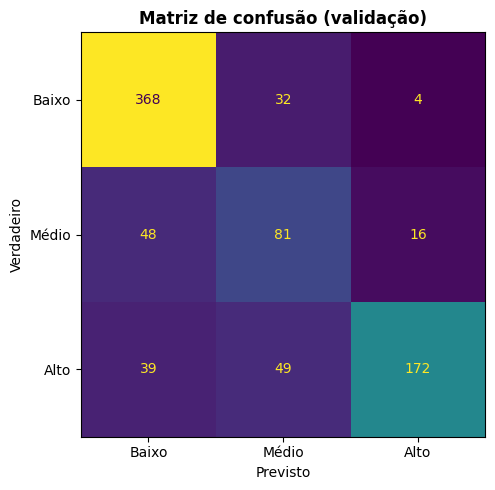


LEITURA DA MATRIZ:
   A diagonal principal concentra as classificações corretas.
   Os elementos fora da diagonal indicam a DIREÇÃO de cada erro.
   Observem a última linha: casos de risco alto classificados como baixo são
   FALSOS NEGATIVOS na classe crítica, e têm custo assimétrico.

              precision    recall  f1-score   support

       Baixo      0.809     0.911     0.857       404
       Médio      0.500     0.559     0.528       145
        Alto      0.896     0.662     0.761       260

    accuracy                          0.768       809
   macro avg      0.735     0.710     0.715       809
weighted avg      0.781     0.768     0.767       809



In [9]:
#@title 🏆 Desempenho na validação { display-mode: "form" }
acuracia = accuracy_score(y_valida, previsoes)
f1 = f1_score(y_valida, previsoes, average="macro")

print("="*60)
print("            DESEMPENHO NO CONJUNTO DE VALIDAÇÃO")
print("="*60)
print(f"  Acurácia ............................. {acuracia*100:5.1f}%")
print(f"  F1-MACRO (métrica oficial) ........... {f1*100:5.1f}%")
print("="*60)
# Faixas calibradas neste conjunto: ~69% e o teto observado com boa configuração.
if   f1 >= .68: print("  Desempenho alto. Verifiquem a estabilidade mudando a validação.")
elif f1 >= .63: print("  Desempenho sólido, com margem de otimização no Bloco 2.")
elif f1 >= .57: print("  Desempenho intermediário. Revisem modelo, profundidade e ZONA LIVRE.")
else:           print("  Desempenho baixo. A configuração atual não captura os padrões.")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_valida, previsoes),
    display_labels=["Baixo","Médio","Alto"]).plot(ax=ax, cmap="viridis", colorbar=False)
ax.set_title("Matriz de confusão (validação)", fontweight="bold")
ax.set_xlabel("Previsto"); ax.set_ylabel("Verdadeiro")
plt.tight_layout(); plt.show()

print("\nLEITURA DA MATRIZ:")
print("   A diagonal principal concentra as classificações corretas.")
print("   Os elementos fora da diagonal indicam a DIREÇÃO de cada erro.")
print("   Observem a última linha: casos de risco alto classificados como baixo são")
print("   FALSOS NEGATIVOS na classe crítica, e têm custo assimétrico.\n")
print(classification_report(y_valida, previsoes,
      target_names=["Baixo","Médio","Alto"], digits=3))

if (previsoes == 1).sum() < 0.05 * len(previsoes):
    print("\n[!] O modelo quase não atribuiu a classe 'Médio'. Isso derruba o F1-macro,")
    print("    que dá peso igual às três classes. Revejam o desbalanceamento do Bloco 1")
    print("    e o parâmetro do Bloco 2 que corrige exatamente esse efeito.")


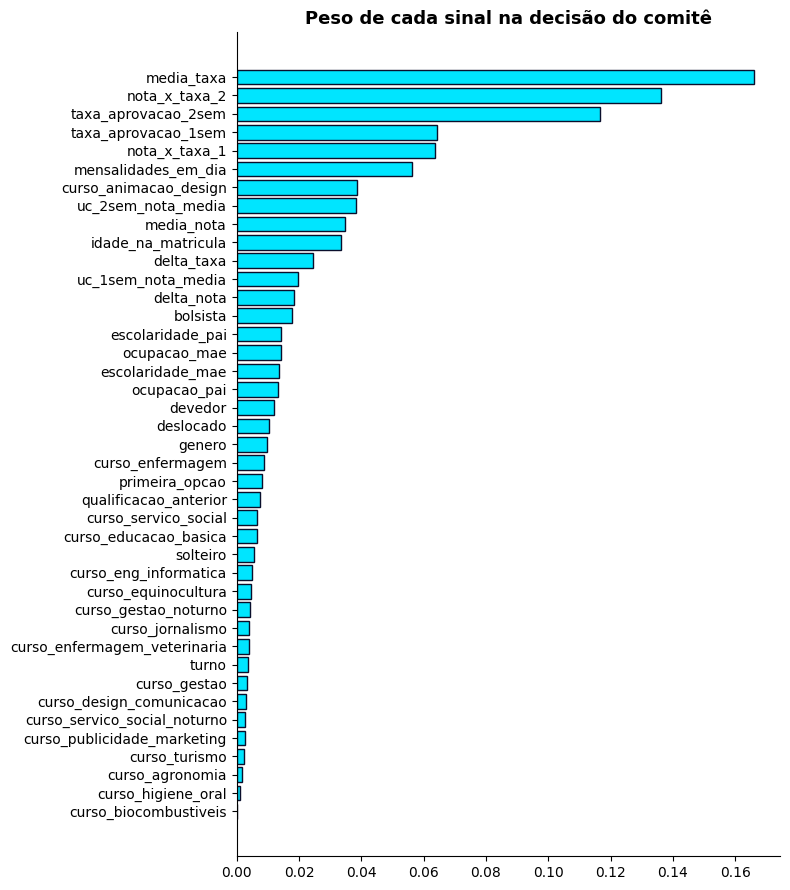

SINAIS DE MAIOR IMPORTÂNCIA:

   1. media_taxa  (0.166)
   2. nota_x_taxa_2  (0.136)
   3. taxa_aprovacao_2sem  (0.116)
   4. taxa_aprovacao_1sem  (0.064)
   5. nota_x_taxa_1  (0.064)
   6. mensalidades_em_dia  (0.056)

Ressalva necessária: importância de variável NÃO é evidência de causalidade.
O modelo identifica associação estatística. Uma variável pode ranquear alto
por estar correlacionada com um fator não observado que é a causa real.
Confundir as duas coisas é um erro frequente na interpretação de modelos.


In [10]:
#@title 🔦 O que o farol está enxergando? { display-mode: "form" }
# A Marina não quer só o alerta. Ela quer entender por quê.
# Sem PCA, a importância volta a ter nome de verdade: cada barra é uma variável
# real da ficha do aluno, não um componente abstrato.

nomes_colunas = engenharia(X_treino).columns
# Média da importância entre os dois membros de floresta que veem as colunas
# derivadas (o boosting não expõe importância por variável).
membros_com_importancia = [m for m, usa_eng in comite
                           if usa_eng and hasattr(m, "feature_importances_")]
imp = pd.Series(np.mean([m.feature_importances_ for m in membros_com_importancia], axis=0),
                index=nomes_colunas).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(imp.index, imp.values, color="#00E5FF", edgecolor="#0A0F2C")
ax.set_title("Peso de cada sinal na decisão do comitê", fontsize=13, fontweight="bold")
ax.spines[["top","right"]].set_visible(False); plt.tight_layout(); plt.show()

print("SINAIS DE MAIOR IMPORTÂNCIA:\n")
for i, (nome, val) in enumerate(imp.sort_values(ascending=False).head(6).items(), 1):
    print(f"   {i}. {nome}  ({val:.3f})")
print("\nRessalva necessária: importância de variável NÃO é evidência de causalidade.")
print("O modelo identifica associação estatística. Uma variável pode ranquear alto")
print("por estar correlacionada com um fator não observado que é a causa real.")
print("Confundir as duas coisas é um erro frequente na interpretação de modelos.")

---
# 🤔 PARADA OBRIGATÓRIA: uma conversa séria

> **Marina:** *"Antes de fechar, preciso colocar uma questão que não é técnica, mas que
> determina se eu posso ou não usar o que vocês construíram."*
>
> *"O mesmo arquivo que diz 'esse estudante precisa de atenção' também pode ser lido como
> 'esse estudante é um problema'. A saída do modelo é idêntica nos dois casos. O que muda é
> o protocolo institucional em volta dela."*
>
> *"Sistemas de predição de risco aplicados a pessoas produzem um efeito documentado: a
> classificação altera o tratamento, o tratamento altera o resultado, e o resultado acaba
> confirmando a classificação. O modelo passa a validar a si mesmo. Se isso acontecer aqui,
> teremos construído uma profecia, não um diagnóstico."*

### Questões para a equipe deliberar

1. **Sobre o custo assimétrico dos erros.** Um falso positivo consome tempo da equipe
   pedagógica com quem não precisava. Um falso negativo deixa sem apoio quem precisava.
   Qual dos dois vocês priorizariam reduzir, e o que se perde nessa escolha? Note que a
   pergunta não tem resposta técnica: ela depende de um juízo de valor que o modelo não faz.

2. **Sobre variáveis socialmente sensíveis.** Variáveis como `mensalidades_em_dia`,
   `devedor` e `bolsista` costumam aparecer entre as mais relevantes. Elas são, na prática,
   indicadores indiretos de condição socioeconômica — e o mesmo vale para `escolaridade_mae`
   e `ocupacao_pai`. Isso levanta uma questão real da área: um modelo que usa esses
   indicadores aumenta a detecção, mas também concentra a sinalização sobre um grupo já
   vulnerável. Remover a variável resolve o problema ou apenas o torna invisível, já que
   outras variáveis correlacionadas permanecem? **Testem:** retirem essas colunas de `X` no
   Bloco 3, reexecutem e comparem o F1-macro e a matriz de confusão.

3. **Sobre governança.** Que restrições de uso vocês anexariam à entrega? Considerem: quem
   pode acessar a lista, por quanto tempo ela é válida, o que explicitamente não pode ser
   feito com ela, e quem responde por uma decisão tomada com base no modelo.

<img src="https://lh3.googleusercontent.com/d/1tt3Sy_3RapDMyyDio5vU04_moy-o_kuA=w1600" width="100%"
     alt="Farol no alto de uma colina à noite, projetando um feixe dourado sobre um caminho por onde estudantes seguem em direção a uma escola iluminada. Outros permanecem parados no escuro, à margem do feixe.">


In [11]:
#@title 📝 O relatório da sua equipe para a Marina { display-mode: "form" }
nome_da_equipe = "Germinare"  #@param {type:"string"}
#@markdown **1. Por que vocês escolheram esse modelo e essa configuração?**
resposta_1 = "Usamos um comite de cinco modelos e decidimos cada peca comparando F1-macro em validacao cruzada de 5 dobras repetida, porque com 809 alunos numa divisao unica o ruido e de +-1,5 ponto e nao daria para distinguir ganho real de sorte. O comite mistura arvores extremamente aleatorizadas, boosting de arvores rasas e uma floresta aleatoria, e a decisao final e a media das probabilidades: cada familia erra de um jeito diferente, entao a media e mais estavel que qualquer membro isolado (melhor membro sozinho 71,2%, comite 71,7%). Tres decisoes pesaram mais que o ajuste fino: class_weight {0: 1.2, 1: 2.1, 2: 0.8} em todos os membros, sem o qual a classe Medio simplesmente deixa de ser prevista e o F1-macro cai para 61-68%; retirar o PCA de 27 componentes do pipeline anterior, que custava cerca de 2 pontos porque reter variancia nao e reter poder preditivo; e limitar a profundidade das arvores para conter o sobreajuste. Testamos e descartamos, com numero na mao, especialistas binarios por classe, ajuste de limiar por classe e poda dos exemplos mal classificados."  #@param {type:"string"}
#@markdown **2. Quais sinais mais pesam no risco de evasão?**
resposta_2 = "O historico academico domina: a taxa de aprovacao do 2o semestre e a nota media do 2o semestre, seguidas pelas mesmas medidas do 1o semestre e pelos sinais derivados que construimos a partir delas (a media dos dois semestres e a interacao nota x taxa de aprovacao). A trajetoria do aluno dentro do curso explica mais do que qualquer caracteristica de cadastro. Vale a ressalva: importancia de variavel indica associacao estatistica, nao causa."  #@param {type:"string"}
#@markdown **3. Que restrições de uso vocês anexariam à entrega, e por quê?**
resposta_3 = "Recomendamos uma revisao da base antes do uso em producao: variaveis como bolsista, genero, ocupacao e escolaridade dos pais sao indicadores indiretos de condicao socioeconomica, e usa-las concentra a sinalizacao sobre um grupo que ja e vulneravel. A lista tambem nao deve circular fora da equipe pedagogica, deve ter prazo de validade curto (ela descreve um semestre, nao o aluno) e nao pode ser usada para nenhuma decisao de matricula, bolsa ou desligamento. A saida do modelo abre uma conversa com o estudante; ela nao decide nada sozinha."  #@param {type:"string"}

relatorio = {"equipe": nome_da_equipe, "modelo": "Comite (ArvoresExtras + Boosting + Floresta Aleatoria)",
             "teste_pct": tamanho_da_validacao, "profundidade": profundidade,
             "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
             "just_modelo": resposta_1, "just_sinais": resposta_2,
             "just_cuidado": resposta_3}
faltando = [k for k in ["equipe", "just_modelo", "just_sinais", "just_cuidado"]
            if not relatorio[k].strip()]
if faltando:
    print("⚠️ Ainda faltam campos:", ", ".join(faltando))
else:
    print("Relatório completo. Prossigam para a submissão.")

Relatório completo. Prossigam para a submissão.


In [12]:
#@title 🚀 Gerar o arquivo de submissão { display-mode: "form" }
#@markdown Rode a célula (▶). Os dois arquivos são baixados automaticamente.
import json, pathlib

PASTA_SUBMISSAO = pathlib.Path("submissoes/tabular")
PASTA_SUBMISSAO.mkdir(parents=True, exist_ok=True)
if "relatorio" not in dir() or not isinstance(relatorio, dict):
    relatorio = {"equipe": "", "modelo": modelo_escolhido,
                 "teste_pct": tamanho_da_validacao, "profundidade": profundidade,
                 "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
                 "just_modelo": "", "just_sinais": "", "just_cuidado": ""}

# Para a submissão, o comitê é RETREINADO nos 3.236 alunos do conjunto público.
# A divisão treino/validação existe para ESTIMAR o desempenho; estimado o número,
# jogar fora 809 alunos na hora de valer não faz sentido — mais dados, menos
# variância. O F1 impresso acima continua sendo a estimativa honesta, porque veio
# do comitê treinado só nos 75%.
print("Retreinando o comitê nos 3.236 alunos do conjunto público...")
comite_final = treinar_comite(X, y, {0: 1.2, 1: 2.1, 2: 0.8})

# O conjunto de teste passa exatamente pelo mesmo caminho: as mesmas colunas
# cruas e a mesma engenharia de atributos. Nenhum ajuste é estimado nele.
palpites = prever(comite_final, dados_teste)

submissao = pd.DataFrame({"id_estudante": IDS_TESTE, "risco_previsto": palpites})

assert len(submissao) == N_TESTE, f"A submissão precisa ter {N_TESTE} linhas."
csv_saida = PASTA_SUBMISSAO / "submissao_tabular.csv"
json_saida = PASTA_SUBMISSAO / "relatorio_tabular.json"
submissao.to_csv(csv_saida, index=False)
with open(json_saida, "w", encoding="utf-8") as f:
    json.dump(relatorio, f, ensure_ascii=False, indent=2)

print("="*60)
print("             ARQUIVOS PRONTOS PARA ENVIO")
print("="*60)
print(f"  submissao_tabular.csv   ({len(submissao)} linhas)")
print("  relatorio_tabular.json")
print("="*60)
print("\n  Distribuição prevista no teste:")
for k, v in pd.Series(palpites).value_counts().sort_index().items():
    print(f"     {NOMES[k]:<6} {v:>4}  ({v/len(palpites)*100:.1f}%)")
display(submissao.head())

try:
    from google.colab import files
    files.download(str(csv_saida))
    files.download(str(json_saida))
    print("\n  Download iniciado. Enviem os dois arquivos na plataforma.")
except ImportError:
    print(f"\n  Fora do Colab: os arquivos estão em {PASTA_SUBMISSAO.resolve()}")

Retreinando o comitê nos 3.236 alunos do conjunto público...
             ARQUIVOS PRONTOS PARA ENVIO
  submissao_tabular.csv   (1078 linhas)
  relatorio_tabular.json

  Distribuição prevista no teste:
     Baixo   578  (53.6%)
     Médio   220  (20.4%)
     Alto    280  (26.0%)


,id_estudante,risco_previsto
0,0,1
1,1,2
2,2,0
3,3,0
4,4,0



  Fora do Colab: os arquivos estão em D:\00 Programacao\OIAA\.git\oiaa\fase1\tabular\submissoes\tabular


---
# 🌟 FIM DA OPERAÇÃO FAROL

> **Marina:** *"Recebi o arquivo e a lista de restrições que vocês anexaram. Levei as duas
> coisas para a reunião pedagógica de segunda."*
>
> *"A discussão que tivemos lá não foi sobre a lista. Foi sobre o que a escola faz com ela,
> e sobre em que ponto a equipe humana entra. Vocês deixaram isso escrito, o que tornou a
> conversa possível."*
>
> *"É um trabalho maduro. Obrigada."*

---

### Competências desenvolvidas neste desafio

- Particionamento entre treino e teste, e a razão estatística por trás dele
- Sobreajuste, subajuste e o compromisso entre viés e variância
- A interface `fit` / `predict` e a lógica de estimadores do `scikit-learn`
- Limitações da acurácia sob desbalanceamento de classes
- Precisão, revocação e a construção do F1-macro
- Leitura direcional da matriz de confusão e custo assimétrico de erros
- Importância de variáveis, e a distinção entre associação e causalidade
- Governança de sistemas preditivos aplicados a pessoas

**Otimização.** Voltem ao Bloco 2 e alterem **um parâmetro por vez**, registrando o efeito
sobre o F1-macro. Variar tudo simultaneamente impede atribuir a melhora a qualquer decisão
específica. Esse método tem nome em experimentação e vale para muito além deste caderno.
